In [20]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [21]:
seed = 42
rng = np.random.default_rng(seed)
box=(0.0, 1.0)
pos = rng.uniform(box[0] + 0.1, box[1] - 0.1, size=2)
print(pos)

[0.71916484 0.45110275]


In [22]:
def simulate_bouncing_ball(n_steps=500, speed=0.09, angle=1.234, dt=0.01, box=(0.0, 1.0), seed=None):
    """
    Simule une balle rebondissant dans une boîte [box[0], box[1]]^2.
    Retourne les positions ET les vitesses (n_steps, 2) chacune --
    la vitesse est ici exposée explicitement dans le state, pas inférée.

    #n_steps : combien de points (positions successives) on veut générer dans la trajectoire
    #speed = 0.4 : vitesse de la balle (norme constante, sauf perte d'énergie si tu ajoutes un coefficient de restitution)
    #angle : angle initial du vecteur vitesse (en radians)
    #dt ("delta time") : le pas de temps entre deux positions
    #box : les limites de la boîte dans laquelle la balle rebondit
    #seed : graine aléatoire, pour la reproductibilité
    """

    rng = np.random.default_rng(seed)

    # point de départ aléatoire, avec une petite marge pour ne pas démarrer collé au mur
    margin = 0.1 * (box[1] - box[0])
    pos = rng.uniform(box[0] + margin, box[1] - margin, size=2)

    vel = speed * np.array([np.cos(angle), np.sin(angle)])  # vecteur vitesse initial (v_x, v_y)

    positions = [pos.copy()]
    velocities = [vel.copy()]

    # Effets de rebond
    for _ in range(n_steps - 1):
        pos = pos + vel * dt       # équation horaire
        for d in range(2):         # pour chaque axe (x, y)
            if pos[d] < box[0]:
                pos[d] = box[0] + (box[0] - pos[d])
                vel[d] *= -1
            elif pos[d] > box[1]:
                pos[d] = box[1] - (pos[d] - box[1])
                vel[d] *= -1
        positions.append(pos.copy())
        velocities.append(vel.copy())

    return np.stack(positions), np.stack(velocities)  # chacun (n_steps, 2)

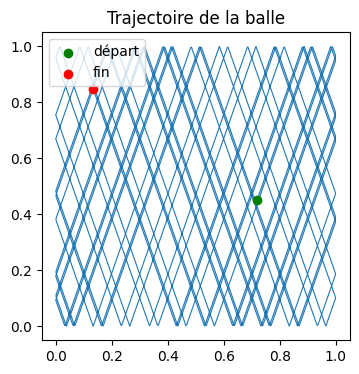

In [23]:
positions, velocities = simulate_bouncing_ball(n_steps=8000, speed=0.4, dt=0.02, box=(0.0, 1.0), seed=seed)

plt.figure(figsize=(4, 4))
plt.plot(positions[:, 0], positions[:, 1], lw=0.8)
plt.scatter(positions[0, 0], positions[0, 1], c="green", label="départ", zorder=5)
plt.scatter(positions[-1, 0], positions[-1, 1], c="red", label="fin", zorder=5)
plt.xlim(-0.05, 1.05); plt.ylim(-0.05, 1.05)
plt.legend(); plt.title("Trajectoire de la balle")
plt.gca().set_aspect("equal")  # évite que le rectangle soit déformé visuellement
plt.show()

In [24]:
class EBM(nn.Module):
    def __init__(self, input_dim=8, hidden_dims=[256, 256, 128], output_dim=1):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.LayerNorm(h))
            layers.append(nn.SiLU())
            prev_dim = h
        layers.append(nn.Linear(prev_dim, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x, y):
        return self.net(torch.cat([x, y], dim=-1))

In [25]:
def make_positive_pairs(positions, velocities, context_len=1):
    """
    Extrait les paires positives (contexte, vrai futur) depuis la trajectoire.
    x = contexte aplati (context_len derniers states), y = vrai state suivant.
    Chaque state = (x, y, vx, vy), dim 4.
    """
    states = np.concatenate([positions, velocities], axis=-1)  # (n_steps, 4)

    contexts, true_nexts = [], []
    n = len(states)

    for t in range(context_len - 1, n - 1):
        ctx = states[t - context_len + 1 : t + 1]   # (context_len, 4)
        true_next = states[t + 1]                    # (4,)
        contexts.append(ctx.flatten())
        true_nexts.append(true_next)

    return (torch.tensor(np.stack(contexts), dtype=torch.float32),
            torch.tensor(np.stack(true_nexts), dtype=torch.float32))

In [26]:
def sample_negatives_ball(ebm, x, n_steps=50, step_size=0.07, noise_scale=0.007,
                           box=(0.0, 1.0), speed_max=0.6):
    """
    Génère des négatifs adversariaux par Langevin dynamics.
    y est un state complet (x, y, vx, vy).
    x = contexte aplati (batch, context_len*4)
    n_steps est le nombre d'itérations dans la dynamique de Langevin
    step_size est la vitesse de descente du grad
    noise_scale est l'échelle de bruit qu'on ajoute à y pour fabriquer des false_next
    Sortie : autant de states labélisés false qu'il y a de contextes dans x
    """
    batch = x.shape[0]

    # init : positions dans la boîte, vitesses dans une plage plausible
    y_pos = torch.empty(batch, 2).uniform_(box[0], box[1])
    y_vel = torch.empty(batch, 2).uniform_(-speed_max, speed_max)
    y = torch.cat([y_pos, y_vel], dim=-1).requires_grad_(True)

    for _ in range(n_steps):
        E = ebm(x, y).sum()
        grad_y, = torch.autograd.grad(E, y)
        noise = torch.randn_like(y) * noise_scale
        y = (y - step_size * grad_y + noise).detach()

        # clamp différencié : positions dans la boîte, vitesses dans une plage physique
        y[:, 0:2] = torch.clamp(y[:, 0:2], box[0], box[1])
        y[:, 2:4] = torch.clamp(y[:, 2:4], -speed_max, speed_max)

        y = y.requires_grad_(True)

    return y.detach()

In [27]:
def train_ball_ebm(ebm, positions, velocities, context_len=3, n_epochs=5000, n_steps=20,
                    step_size=0.1, lr=1e-3, reg_weight=0.01, batch_size=64, noise_scale=0.01,
                    box=(0.0, 1.0), speed_max=0.6):
    opt = torch.optim.Adam(ebm.parameters(), lr=lr)

    contexts, true_nexts = make_positive_pairs(positions, velocities, context_len=context_len)
    n_samples = contexts.shape[0]

    for epoch in range(n_epochs):
        idx = torch.randint(0, n_samples, (batch_size,))
        x_batch = contexts[idx]
        y_pos = true_nexts[idx]

        y_neg = sample_negatives_ball(ebm, x_batch, step_size=step_size, n_steps=n_steps,
                                       noise_scale=noise_scale, box=box, speed_max=speed_max)

        E_pos = ebm(x_batch, y_pos)
        E_neg = ebm(x_batch, y_neg)

        contrastive = torch.relu(1.0 + E_pos - E_neg).mean()
        reg = reg_weight * (E_pos**2 + E_neg**2).mean()
        loss = contrastive + reg

        opt.zero_grad()
        loss.backward()
        opt.step()

        if epoch % 200 == 0:
            print(f"epoch {epoch:5d} | loss {loss.item():.4f} | E_pos {E_pos.mean().item():.3f} | "
                  f"E_neg {E_neg.mean().item():.3f} | |E_neg-E_pos| {torch.abs(E_neg.mean() - E_pos.mean()).item():.3f}")

    return ebm

In [28]:
def predict_next_via_energy_descent(ebm, context, n_steps=20, lr=0.05,
                                     box=(0.0, 1.0), speed_max=0.6):
    """
    context : tensor (context_len, 4), states passés (x, y, vx, vy) non aplatis.
    """
    candidate = context[-1].clone().unsqueeze(0).requires_grad_(True)  # init = dernier state
    x = context.flatten().unsqueeze(0)

    for _ in range(n_steps):
        energy = ebm(x, candidate)
        grad = torch.autograd.grad(energy.sum(), candidate)[0]
        candidate = (candidate - lr * grad).detach()

        # clamp différencié : positions dans la boîte, vitesses dans une plage physique
        candidate[:, 0:2] = torch.clamp(candidate[:, 0:2], box[0], box[1])
        candidate[:, 2:4] = torch.clamp(candidate[:, 2:4], -speed_max, speed_max)

        candidate = candidate.requires_grad_(True)

    return candidate.detach().squeeze(0)

In [29]:
context_len = 3
input_dim = context_len * 4 + 4   # = 3*4 + 4 = 16

ebm_shallow_0 = EBM(input_dim=input_dim, hidden_dims=[64])
ebm_deep_0    = EBM(input_dim=input_dim, hidden_dims=[256, 256, 128])

In [30]:
context_len = 3
positions, velocities = simulate_bouncing_ball(n_steps=10000, speed=0.07, dt=0.01, box=(0.0, 1.0), seed=seed)
ctx, true_next = make_positive_pairs(positions, velocities, context_len=context_len)

print(ctx.shape)  

false_next = sample_negatives_ball(ebm_shallow_0, ctx)
print(false_next.size())

torch.Size([9997, 12])
torch.Size([9997, 4])


In [31]:
ebm_shallow_0 = train_ball_ebm(
    ebm_shallow_0,
    positions,
    velocities,
    context_len=3,   # doit matcher input_dim=16 utilisé à la création du modèle
    n_epochs=5000,
)

epoch     0 | loss 1.4865 | E_pos 0.456 | E_neg -0.028 | |E_neg-E_pos| 0.484
epoch   200 | loss 0.9951 | E_pos -0.073 | E_neg -0.067 | |E_neg-E_pos| 0.005
epoch   400 | loss 0.9989 | E_pos -0.021 | E_neg -0.020 | |E_neg-E_pos| 0.001
epoch   600 | loss 0.9991 | E_pos -0.005 | E_neg -0.004 | |E_neg-E_pos| 0.001
epoch   800 | loss 0.0651 | E_pos -0.710 | E_neg 1.278 | |E_neg-E_pos| 1.988
epoch  1000 | loss 0.0169 | E_pos -0.561 | E_neg 0.711 | |E_neg-E_pos| 1.272
epoch  1200 | loss 0.0086 | E_pos -0.468 | E_neg 0.749 | |E_neg-E_pos| 1.217
epoch  1400 | loss 0.0182 | E_pos -0.526 | E_neg 0.838 | |E_neg-E_pos| 1.364
epoch  1600 | loss 0.0313 | E_pos -0.731 | E_neg 0.655 | |E_neg-E_pos| 1.386
epoch  1800 | loss 0.0069 | E_pos -0.552 | E_neg 0.618 | |E_neg-E_pos| 1.170
epoch  2000 | loss 0.0077 | E_pos -0.638 | E_neg 0.569 | |E_neg-E_pos| 1.207
epoch  2200 | loss 0.0183 | E_pos -0.497 | E_neg 0.597 | |E_neg-E_pos| 1.094
epoch  2400 | loss 0.0102 | E_pos -0.847 | E_neg 0.514 | |E_neg-E_pos| 1.

In [32]:
ebm_deep_0 = train_ball_ebm(
    ebm_deep_0,
    positions,
    velocities,
    context_len=3,   # doit matcher input_dim=16 utilisé à la création du modèle
    n_epochs=5000,
)

epoch     0 | loss 1.3277 | E_pos 0.366 | E_neg 0.040 | |E_neg-E_pos| 0.326
epoch   200 | loss 0.9996 | E_pos 0.027 | E_neg 0.027 | |E_neg-E_pos| 0.000
epoch   400 | loss 0.0471 | E_pos -0.533 | E_neg 0.768 | |E_neg-E_pos| 1.301
epoch   600 | loss 0.0086 | E_pos -0.484 | E_neg 0.771 | |E_neg-E_pos| 1.255
epoch   800 | loss 0.0126 | E_pos -0.584 | E_neg 0.682 | |E_neg-E_pos| 1.265
epoch  1000 | loss 0.0061 | E_pos -0.550 | E_neg 0.554 | |E_neg-E_pos| 1.104
epoch  1200 | loss 0.0057 | E_pos -0.541 | E_neg 0.526 | |E_neg-E_pos| 1.067
epoch  1400 | loss 0.0070 | E_pos -0.588 | E_neg 0.588 | |E_neg-E_pos| 1.176
epoch  1600 | loss 0.0082 | E_pos -0.497 | E_neg 0.751 | |E_neg-E_pos| 1.248
epoch  1800 | loss 0.0060 | E_pos -0.538 | E_neg 0.551 | |E_neg-E_pos| 1.089
epoch  2000 | loss 0.0073 | E_pos -0.622 | E_neg 0.576 | |E_neg-E_pos| 1.198
epoch  2200 | loss 0.0059 | E_pos -0.557 | E_neg 0.532 | |E_neg-E_pos| 1.089
epoch  2400 | loss 0.0059 | E_pos -0.553 | E_neg 0.537 | |E_neg-E_pos| 1.090
e

In [33]:
def rollout_ebm(ebm, positions0, velocities0, context_len, n_steps,
                 box=(0.0, 1.0), speed_max=0.6, n_langevin_steps=20, lr=0.05):
    """
    Fait rouler le modèle en autoregressif à partir d'un contexte initial
    (context_len premiers vrais states), puis prédit la suite en boucle
    fermée (le modèle se nourrit de ses propres prédictions).
    """
    states0 = np.concatenate([positions0, velocities0], axis=-1)  # (context_len, 4)
    context = torch.tensor(states0[:context_len], dtype=torch.float32)  # (context_len, 4)

    predicted_states = [s.clone() for s in context]

    for _ in range(n_steps - context_len):
        next_state = predict_next_via_energy_descent(
            ebm, context, n_steps=n_langevin_steps, lr=lr, box=box, speed_max=speed_max
        )  # (4,)
        predicted_states.append(next_state)

        # glisse le contexte : on enlève le plus ancien, on ajoute le nouveau
        context = torch.cat([context[1:], next_state.unsqueeze(0)], dim=0)

    return torch.stack(predicted_states).numpy()  # (n_steps, 4)

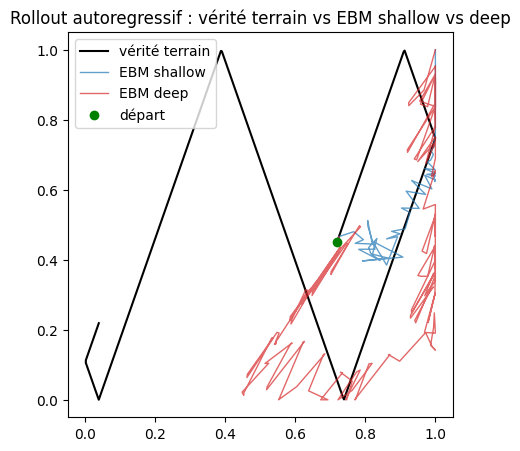

In [34]:
n_steps = 500
context_len = 3

positions, velocities = simulate_bouncing_ball(n_steps=n_steps, speed=0.4, dt=0.02, box=(0.0, 1.0), seed=42)

pred_shallow = rollout_ebm(ebm_shallow_0, positions, velocities, context_len, n_steps)
pred_deep    = rollout_ebm(ebm_deep_0, positions, velocities, context_len, n_steps)

plt.figure(figsize=(5, 5))
plt.plot(positions[:, 0], positions[:, 1], lw=1.5, color="black", label="vérité terrain")
plt.plot(pred_shallow[:, 0], pred_shallow[:, 1], lw=1.0, color="tab:blue", alpha=0.7, label="EBM shallow")
plt.plot(pred_deep[:, 0], pred_deep[:, 1], lw=1.0, color="tab:red", alpha=0.7, label="EBM deep")
plt.scatter(positions[0, 0], positions[0, 1], c="green", zorder=5, label="départ")
plt.xlim(-0.05, 1.05); plt.ylim(-0.05, 1.05)
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Rollout autoregressif : vérité terrain vs EBM shallow vs deep")
plt.show()

On soupçonne une accumulation de petites erreur à chaque étape et qui fini par exploser.Pour vérifier celà, voyons l'erreur à un pas.

In [35]:
def eval_1step_error(ebm, positions, velocities, context_len, n_langevin_steps=20, lr=0.05,
                      box=(0.0, 1.0), speed_max=0.6):
    states = np.concatenate([positions, velocities], axis=-1)  # (n_steps, 4)
    n = len(states)

    errors = []
    for t in range(n - context_len):
        context = torch.tensor(states[t : t + context_len], dtype=torch.float32)
        true_next = states[t + context_len]

        pred = predict_next_via_energy_descent(
            ebm, context, n_steps=n_langevin_steps, lr=lr, box=box, speed_max=speed_max
        )
        err = np.linalg.norm(pred.numpy() - true_next)
        errors.append(err)

    return np.array(errors)

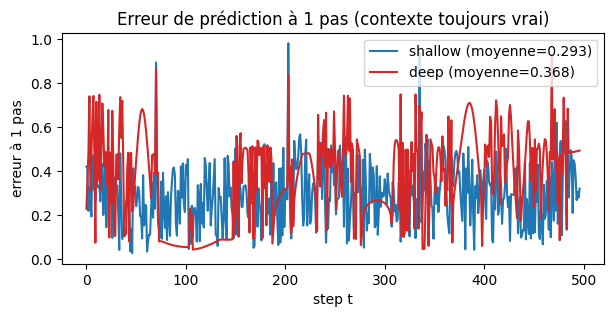

In [36]:
err_shallow = eval_1step_error(ebm_shallow_0, positions, velocities, context_len=3)
err_deep = eval_1step_error(ebm_deep_0, positions, velocities, context_len=3)

plt.figure(figsize=(7, 3))
plt.plot(err_shallow, label=f"shallow (moyenne={err_shallow.mean():.3f})", color="tab:blue")
plt.plot(err_deep, label=f"deep (moyenne={err_deep.mean():.3f})", color="tab:red")
plt.xlabel("step t"); plt.ylabel("erreur à 1 pas")
plt.legend(); plt.title("Erreur de prédiction à 1 pas (contexte toujours vrai)")
plt.show()

In [38]:
context_len = 3
t = 5  # un point pas trop loin du début, avant que ça diverge trop
states = np.concatenate([positions, velocities], axis=-1)
context = torch.tensor(states[t:t+context_len], dtype=torch.float32)

candidate = context[-1].clone().unsqueeze(0).requires_grad_(True)
x = context.flatten().unsqueeze(0)

for step in range(20):
    energy = ebm_deep_0(x, candidate)
    grad, = torch.autograd.grad(energy.sum(), candidate)

    grad_pos_norm = grad[:, 0:2].norm().item()
    grad_vel_norm = grad[:, 2:4].norm().item()
    print(f"step {step:2d} | grad_pos {grad_pos_norm:.4f} | grad_vel {grad_vel_norm:.4f}")

    candidate = (candidate - 0.05 * grad).detach().requires_grad_(True)

step  0 | grad_pos 0.6530 | grad_vel 5.5234
step  1 | grad_pos 0.0187 | grad_vel 0.0778
step  2 | grad_pos 0.0184 | grad_vel 0.0850
step  3 | grad_pos 0.0179 | grad_vel 0.0938
step  4 | grad_pos 0.0172 | grad_vel 0.1049
step  5 | grad_pos 0.0164 | grad_vel 0.1191
step  6 | grad_pos 0.0155 | grad_vel 0.1382
step  7 | grad_pos 0.0144 | grad_vel 0.1650
step  8 | grad_pos 0.0141 | grad_vel 0.2054
step  9 | grad_pos 0.0181 | grad_vel 0.2734
step 10 | grad_pos 0.0356 | grad_vel 0.4104
step 11 | grad_pos 0.1027 | grad_vel 0.8060
step 12 | grad_pos 0.7588 | grad_vel 4.0076
step 13 | grad_pos 2.2467 | grad_vel 13.9946
step 14 | grad_pos 0.0073 | grad_vel 0.0092
step 15 | grad_pos 0.0073 | grad_vel 0.0092
step 16 | grad_pos 0.0073 | grad_vel 0.0092
step 17 | grad_pos 0.0072 | grad_vel 0.0092
step 18 | grad_pos 0.0072 | grad_vel 0.0091
step 19 | grad_pos 0.0072 | grad_vel 0.0091
